In [5]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [6]:
from pathlib import Path

# ============================================================
# COLOR WITH KRISHNA — AUTOMATION STUDIO
# Project structure
# ============================================================

BASE = Path("/kaggle/working/COLOR_WITH_KRISHNA_STUDIO")

folders = [
    "00_config",
    "01_characters",
    "01_characters/reference",
    "02_volume_02",
    "02_volume_02/color",
    "02_volume_02/coloring",
    "02_volume_02/spot_art",
    "03_layout",
    "04_output",
]

for folder in folders:
    path = BASE / folder
    path.mkdir(parents=True, exist_ok=True)

print("Project created at:")
print(BASE)

print("\nFolders:")
for path in BASE.rglob("*"):
    if path.is_dir():
        print("📁", path.relative_to(BASE))

Project created at:
/kaggle/working/COLOR_WITH_KRISHNA_STUDIO

Folders:
📁 00_config
📁 03_layout
📁 02_volume_02
📁 01_characters
📁 04_output
📁 02_volume_02/color
📁 02_volume_02/coloring
📁 02_volume_02/spot_art
📁 01_characters/reference


In [7]:
import json

style = {
    "project": {
        "name": "Color With Krishna",
        "series": "Color With Krishna",
        "volume": 2,
        "book_title": "The Little Butter Thief",
        "target_age": "2-6",
        "format": "children's story and coloring book",
        "visual_goal": "warm, joyful, gentle, preschool-friendly Indian storybook"
    },

    "art_direction": {
        "overall_style": [
            "cute preschool storybook illustration",
            "chibi-inspired proportions",
            "soft rounded shapes",
            "warm expressive characters",
            "friendly and joyful mood",
            "simple readable compositions",
            "Indian cultural setting",
            "Gokul village atmosphere"
        ],

        "character_design": {
            "proportions": "large head, small body, short limbs, rounded childlike proportions",
            "faces": "round, soft and expressive",
            "eyes": "large, warm, expressive eyes",
            "expressions": "gentle, playful, happy, curious",
            "hands": "small rounded childlike hands",
            "feet": "small rounded feet"
        },

        "environment": [
            "Gokul village courtyards",
            "simple mud and plaster houses",
            "wooden pillars",
            "earthen butter pots",
            "simple village trees",
            "green meadows",
            "warm rural Indian atmosphere"
        ]
    },

    "krishna_visual_identity": {
        "skin": "soft Krishna blue",
        "hair": "short curly black hair",
        "face": "round chubby baby face",
        "eyes": "large expressive brown eyes",
        "tilak": "small sandalwood tilak",
        "headpiece": "single peacock feather",
        "clothing": "yellow dhoti",
        "jewelry": [
            "simple gold necklace",
            "small gold bracelets",
            "small gold anklets"
        ],
        "body_type": "adorable chubby preschool-age child",
        "overall_expression": "playful, innocent, mischievous but lovable"
    },

    "color_palette": {
        "skin_blue": "soft Krishna blue",
        "yellow": "warm golden yellow",
        "green": "fresh meadow green",
        "brown": "warm earthy brown",
        "cream": "warm butter cream",
        "gold": "soft traditional gold",
        "background": "warm light natural tones",
        "line_art": "pure black",
        "paper": "pure white"
    },

    "color_master_rules": {
        "purpose": "full-color reference artwork used as the source for matching coloring pages",
        "rendering": [
            "clean shapes",
            "clear character silhouettes",
            "simple readable details",
            "soft dimensionality",
            "warm colors",
            "minimal visual clutter"
        ],
        "avoid": [
            "photorealism",
            "dark horror mood",
            "dramatic violence",
            "realistic adult proportions",
            "excessive environmental detail",
            "visual clutter",
            "text inside generated artwork",
            "logos",
            "watermarks"
        ]
    },

    "coloring_page_rules": {
        "background": "pure white",
        "line_color": "pure black",
        "line_weight": "thick and bold",
        "line_quality": [
            "clean",
            "smooth",
            "rounded",
            "continuous",
            "easy for preschool children to color"
        ],
        "composition": [
            "large enclosed coloring areas",
            "clear foreground characters",
            "simple background objects",
            "strong separation between objects"
        ],
        "detail_level": "low to moderate",
        "shading": False,
        "gradients": False,
        "cross_hatching": False,
        "grey_tones": False,
        "color_fills": False,
        "textures": False,
        "text": False,
        "watermark": False
    },

    "brand_rules": {
        "series_tone": [
            "loving",
            "playful",
            "gentle",
            "educational",
            "culturally respectful",
            "family friendly"
        ],
        "age_appropriateness": "2-6 years",
        "avoid": [
            "fear",
            "punishment-focused imagery",
            "violence",
            "threatening expressions",
            "distressing scenes"
        ]
    },

    "generation_rules": {
        "generate_artwork_only": True,
        "generate_text": False,
        "generate_titles": False,
        "generate_page_numbers": False,
        "generate_chhota_task_box": False,
        "generate_color_thumbnail": False,
        "layout_added_programmatically": True
    }
}

style_path = BASE / "00_config/style.json"

with open(style_path, "w", encoding="utf-8") as f:
    json.dump(style, f, indent=2, ensure_ascii=False)

print(f"Created: {style_path}")

Created: /kaggle/working/COLOR_WITH_KRISHNA_STUDIO/00_config/style.json


In [8]:
characters = {
    "series": "Color With Krishna",

    "character_consistency_rules": {
        "priority": "very_high",
        "preserve_across_scenes": [
            "face shape",
            "eye shape",
            "skin color",
            "hair style",
            "peacock feather",
            "tilak",
            "body proportions",
            "clothing identity",
            "age appearance"
        ],
        "avoid_character_drift": True
    },

    "characters": {

        "krishna": {
            "id": "krishna",
            "name": "Bal Gopal",
            "role": "The Little Butter Thief",

            "age_appearance": "preschool-age child",

            "physical_identity": {
                "face": "round, chubby, adorable child face",
                "cheeks": "soft and slightly chubby",
                "eyes": "large expressive warm brown eyes",
                "nose": "small rounded childlike nose",
                "mouth": "small expressive smiling mouth",
                "skin": "soft Krishna blue",
                "hair": "short curly black hair",
                "body": "small chubby child proportions",
                "hands": "small rounded hands",
                "feet": "small rounded feet"
            },

            "signature_features": [
                "single peacock feather",
                "small sandalwood tilak",
                "yellow dhoti",
                "simple gold necklace",
                "small gold bracelets",
                "small gold anklets"
            ],

            "personality_visuals": [
                "playful",
                "mischievous",
                "innocent",
                "curious",
                "loving",
                "joyful"
            ],

            "expression_range": [
                "happy smile",
                "curious look",
                "playful grin",
                "surprised expression",
                "pretending to be innocent",
                "gentle sleepy expression"
            ],

            "negative_character_rules": [
                "no adult Krishna",
                "no teenage Krishna",
                "no muscular body",
                "no realistic adult proportions",
                "no angry face",
                "no frightening expression",
                "no facial hair",
                "no modern clothing",
                "no crown unless specifically requested"
            ]
        },

        "yashoda": {
            "id": "yashoda",
            "name": "Yashoda Maiya",
            "role": "Krishna's loving mother",

            "appearance": {
                "age": "warm maternal adult",
                "face": "kind, rounded, nurturing expression",
                "hair": "dark hair",
                "clothing": "traditional Indian sari",
                "jewelry": "simple traditional Indian jewelry"
            },

            "personality_visuals": [
                "loving",
                "patient",
                "warm",
                "protective",
                "playfully exasperated"
            ],

            "negative_rules": [
                "no angry threatening expression",
                "no modern clothing",
                "no excessive jewelry",
                "no glamorous fashion styling"
            ]
        },

        "cowherd_boy": {
            "id": "cowherd_boy",
            "name": "Gokul Cowherd Friend",
            "role": "Krishna's childhood friend",

            "appearance": {
                "age": "preschool-age child",
                "body": "small child proportions",
                "clothing": "simple traditional village clothing",
                "style": "same illustration language as Krishna"
            },

            "personality_visuals": [
                "playful",
                "friendly",
                "energetic",
                "joyful"
            ]
        },

        "gopi": {
            "id": "gopi",
            "name": "Gopi",
            "role": "Gokul village woman",

            "appearance": {
                "age": "young adult woman",
                "clothing": "traditional Indian sari",
                "style": "warm preschool storybook illustration"
            },

            "personality_visuals": [
                "warm",
                "friendly",
                "playfully concerned",
                "gentle"
            ]
        },

        "monkey": {
            "id": "monkey",
            "name": "Gokul Monkey",
            "role": "Krishna's playful butter companion",

            "appearance": {
                "style": "cute simplified storybook monkey",
                "expression": "friendly and playful"
            }
        },

        "squirrel": {
            "id": "squirrel",
            "name": "Gokul Squirrel",
            "role": "Small friendly animal companion",

            "appearance": {
                "style": "cute simplified children's storybook squirrel",
                "expression": "friendly and curious"
            }
        },

        "bird": {
            "id": "bird",
            "name": "Gokul Bird",
            "role": "Small friendly bird",

            "appearance": {
                "style": "cute simplified children's storybook bird",
                "expression": "friendly and cheerful"
            }
        }
    }
}

characters_path = BASE / "00_config/characters.json"

with open(characters_path, "w", encoding="utf-8") as f:
    json.dump(characters, f, indent=2, ensure_ascii=False)

print(f"Created: {characters_path}")

Created: /kaggle/working/COLOR_WITH_KRISHNA_STUDIO/00_config/characters.json


In [9]:
# ============================================================
# Verify configuration files
# ============================================================

for path in [style_path, characters_path]:
    print("\n" + "=" * 60)
    print(path.name)
    print("=" * 60)

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    print(json.dumps(data, indent=2, ensure_ascii=False)[:3000])

print("\n✅ Configuration files loaded successfully.")


style.json
{
  "project": {
    "name": "Color With Krishna",
    "series": "Color With Krishna",
    "volume": 2,
    "book_title": "The Little Butter Thief",
    "target_age": "2-6",
    "format": "children's story and coloring book",
    "visual_goal": "warm, joyful, gentle, preschool-friendly Indian storybook"
  },
  "art_direction": {
    "overall_style": [
      "cute preschool storybook illustration",
      "chibi-inspired proportions",
      "soft rounded shapes",
      "warm expressive characters",
      "friendly and joyful mood",
      "simple readable compositions",
      "Indian cultural setting",
      "Gokul village atmosphere"
    ],
    "character_design": {
      "proportions": "large head, small body, short limbs, rounded childlike proportions",
      "faces": "round, soft and expressive",
      "eyes": "large, warm, expressive eyes",
      "expressions": "gentle, playful, happy, curious",
      "hands": "small rounded childlike hands",
      "feet": "small rounded 

In [10]:
# ============================================================
# STEP 5 — CHARACTER MASTER ASSETS
# ============================================================

master_folders = [
    BASE / "01_characters/masters",
    BASE / "01_characters/poses",
    BASE / "01_characters/expressions",
    BASE / "01_characters/reference"
]

for folder in master_folders:
    folder.mkdir(parents=True, exist_ok=True)

print("Character asset folders created.")

for folder in master_folders:
    print("📁", folder.relative_to(BASE))

Character asset folders created.
📁 01_characters/masters
📁 01_characters/poses
📁 01_characters/expressions
📁 01_characters/reference


In [11]:

!git clone https://github.com/Comfy-Org/ComfyUI.git /kaggle/working/ComfyUI

Cloning into '/kaggle/working/ComfyUI'...
remote: Enumerating objects: 60223, done.
remote: Counting objects: 100% (276/276), done.
remote: Compressing objects: 100% (142/142), done.
remote: Total 60223 (delta 208), reused 134 (delta 134), pack-reused 59947 (from 3)
Receiving objects: 100% (60223/60223), 102.50 MiB | 23.33 MiB/s, done.
Resolving deltas: 100% (41679/41679), done.


In [12]:

%cd /kaggle/working/ComfyUI
!pip install -r requirements.txt

/kaggle/working/ComfyUI
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.6/25.6 MB 74.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.3/24.3 MB 80.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.8/65.8 MB 31.8 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 432.9/432.9 kB 21.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.4/82.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 89.3 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 19.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.2/94.2 MB 20.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.7/29.7 MB 51.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 MB 19.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.1/89.1 MB 20.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━

In [13]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2))

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
GPU memory (GB): 15.64


In [14]:

%cd /kaggle/working

!git clone https://github.com/Comfy-Org/ComfyUI.git

/kaggle/working
fatal: destination path 'ComfyUI' already exists and is not an empty directory.


In [15]:

%cd /kaggle/working/ComfyUI

!pip install -r requirements.txt

/kaggle/working/ComfyUI


In [16]:

from pathlib import Path

comfy_dir = Path("/kaggle/working/ComfyUI")

print("ComfyUI folder exists:", comfy_dir.exists())
print("Main application exists:", (comfy_dir / "main.py").exists())

ComfyUI folder exists: True
Main application exists: True


In [32]:
!pip install -q pyngrok

In [33]:

import subprocess
import time
import requests
from pathlib import Path
from kaggle_secrets import UserSecretsClient
from pyngrok import ngrok

COMFY_DIR = Path("/kaggle/working/ComfyUI")
LOG_FILE = open("/kaggle/working/comfyui.log", "w")

# Check the installation
assert (COMFY_DIR / "main.py").exists(), (
    "ComfyUI is not installed. Complete the installation steps first."
)

# Retrieve the token securely from Kaggle Secrets
token = UserSecretsClient().get_secret("ngrok-auth")
ngrok.set_auth_token(token)

# Start ComfyUI
process = subprocess.Popen(
    [
        "python", "main.py",
        "--listen", "127.0.0.1",
        "--port", "8188"
    ],
    cwd=str(COMFY_DIR),
    stdout=LOG_FILE,
    stderr=subprocess.STDOUT
)

# Wait for the local server
local_url = "http://127.0.0.1:8188"
for attempt in range(60):
    if process.poll() is not None:
        raise RuntimeError(
            "ComfyUI stopped unexpectedly. Check /kaggle/working/comfyui.log"
        )
    try:
        response = requests.get(local_url, timeout=2)
        if response.status_code == 200:
            break
    except requests.RequestException:
        pass
    time.sleep(2)
else:
    raise RuntimeError(
        "ComfyUI did not respond in time. Check its log file."
    )

print("ComfyUI server is running.")

# Create the temporary browser-access tunnel
tunnel = ngrok.connect(8188, "http")
print("Open this URL in your browser:")
print(tunnel.public_url)

ComfyUI server is running.
Open this URL in your browser:
https://anchovy-antennae-barcode.ngrok-free.dev


In [34]:
import os
import signal

!pkill -f "python main.py" || true

print("Existing ComfyUI process stopped.")

Existing ComfyUI process stopped.


In [35]:
from pyngrok import ngrok

ngrok.kill()

print("Old ngrok tunnel closed.")

Old ngrok tunnel closed.


In [36]:
import subprocess
import time
import requests
from pathlib import Path

COMFY_DIR = Path("/kaggle/working/ComfyUI")
LOG_FILE = open("/kaggle/working/comfyui.log", "w")

process = subprocess.Popen(
    [
        "python",
        "main.py",
        "--listen", "127.0.0.1",
        "--port", "8188",
        "--enable-cors-header"
    ],
    cwd=str(COMFY_DIR),
    stdout=LOG_FILE,
    stderr=subprocess.STDOUT
)

print("Starting ComfyUI...")

for attempt in range(60):
    if process.poll() is not None:
        print("ComfyUI stopped unexpectedly.")
        break

    try:
        r = requests.get(
            "http://127.0.0.1:8188",
            timeout=2
        )

        if r.status_code == 200:
            print("ComfyUI is running locally.")
            break

    except requests.RequestException:
        pass

    time.sleep(2)

else:
    print("ComfyUI did not start within the expected time.")

Starting ComfyUI...
ComfyUI is running locally.


In [37]:
from pyngrok import ngrok

tunnel = ngrok.connect(
    addr=8188,
    proto="http"
)

print("NEW COMFYUI URL:")
print(tunnel.public_url)

NEW COMFYUI URL:
https://anchovy-antennae-barcode.ngrok-free.dev


In [38]:

from pathlib import Path

models_dir = Path(
    "/kaggle/working/ComfyUI/models/checkpoints"
)
models_dir.mkdir(parents=True, exist_ok=True)

print("Model folder:", models_dir)
print("Folder exists:", models_dir.exists())

Model folder: /kaggle/working/ComfyUI/models/checkpoints
Folder exists: True


In [39]:

from pathlib import Path
import subprocess

model_path = Path(
    "/kaggle/working/ComfyUI/models/checkpoints/"
    "sd_xl_base_1.0.safetensors"
)

model_url = (
    "https://huggingface.co/stabilityai/"
    "stable-diffusion-xl-base-1.0/resolve/main/"
    "sd_xl_base_1.0.safetensors"
)

if model_path.exists() and model_path.stat().st_size > 1_000_000_000:
    print("Model file already exists:", model_path)
else:
    result = subprocess.run([
        "wget", "-c", "--show-progress",
        "-O", str(model_path), model_url
    ])
    if result.returncode != 0:
        print("Download failed. Check internet access and model permissions.")
    elif model_path.exists() and model_path.stat().st_size > 1_000_000_000:
        print("Model downloaded successfully!")
    else:
        print("Download appears incomplete. Check the file size.")

Model file already exists: /kaggle/working/ComfyUI/models/checkpoints/sd_xl_base_1.0.safetensors


In [40]:
import os
import signal

!pkill -f "python main.py" || true

print("Existing ComfyUI process stopped.")

Existing ComfyUI process stopped.


In [41]:
from pyngrok import ngrok

ngrok.kill()

print("Old ngrok tunnel closed.")

Old ngrok tunnel closed.


In [43]:
import subprocess
import time
import requests
from pathlib import Path

COMFY_DIR = Path("/kaggle/working/ComfyUI")
LOG_FILE = open("/kaggle/working/comfyui.log", "w")

process = subprocess.Popen(
    [
        "python",
        "main.py",
        "--listen", "127.0.0.1",
        "--port", "8188",
        "--enable-cors-header"
    ],
    cwd=str(COMFY_DIR),
    stdout=LOG_FILE,
    stderr=subprocess.STDOUT
)

print("Starting ComfyUI...")

for attempt in range(60):
    if process.poll() is not None:
        print("ComfyUI stopped unexpectedly.")
        break

    try:
        r = requests.get(
            "http://127.0.0.1:8188",
            timeout=2
        )

        if r.status_code == 200:
            print("ComfyUI is running locally.")
            break

    except requests.RequestException:
        pass

    time.sleep(2)

else:
    print("ComfyUI did not start within the expected time.")

Starting ComfyUI...
ComfyUI is running locally.


In [44]:
from pyngrok import ngrok

tunnel = ngrok.connect(
    addr=8188,
    proto="http"
)

print("NEW COMFYUI URL:")
print(tunnel.public_url)

NEW COMFYUI URL:
https://anchovy-antennae-barcode.ngrok-free.dev


In [45]:
import requests

url = "http://127.0.0.1:8188"

try:
    r = requests.get(url, timeout=10)
    print("Status:", r.status_code)
    print("Server:", r.text[:200])
except Exception as e:
    print("ERROR:", e)

Status: 200
Server: <!doctype html><html lang="en"><head><link rel="stylesheet" href="user.css"><link rel="stylesheet" href="api/userdata/user.css"><meta charset="UTF-8"/><link rel="icon" type="image/x-icon" href="./asse


In [46]:
!ps aux | grep "[m]ain.py"

root         232  0.7  3.9 16461616 1286460 ?    Sl   10:04   0:29 python3 main.py --listen 127.0.0.1 --port 8188


In [47]:
main.py --listen 127.0.0.1 --port 8188 --enable-cors-header

SyntaxError: invalid syntax (2465513500.py, line 1)

In [48]:
from pyngrok import ngrok

# Remove existing tunnels
ngrok.kill()

# Create fresh tunnel
tunnel = ngrok.connect(
    "http://127.0.0.1:8188"
)

print("====================================")
print("NEW COMFYUI URL")
print("====================================")
print(tunnel.public_url)

NEW COMFYUI URL
https://anchovy-antennae-barcode.ngrok-free.dev


In [49]:
from pathlib import Path

log = Path("/kaggle/working/comfyui.log")

print("\n".join(
    log.read_text(errors="replace").splitlines()[-40:]
))

If you are on nvidia 20 series and above it is required that you update your pytorch to cu130 or higher.

[INFO] Found comfy_kitchen backend cuda: {'available': True, 'disabled': True, 'unavailable_reason': None, 'capabilities': ['adaln', 'apply_rope', 'apply_rope1', 'apply_rope1_', 'apply_rope_', 'apply_rope_split_half', 'apply_rope_split_half1', 'apply_rope_split_half1_', 'apply_rope_split_half_', 'closest_point_on_mesh', 'connected_components', 'convrot_w4a4_linear', 'delaunay3d', 'dequantize_convrot_w4a4_weight', 'dequantize_int8_convrot_weight', 'dequantize_int8_convrot_weight_dtype', 'dequantize_int8_simple', 'dequantize_int8_simple_dtype', 'dequantize_nvfp4', 'dequantize_per_tensor_fp8', 'dequantize_w4a8_int8_weight', 'edge_collapse_checks', 'fp16_conv3d', 'fp16_conv3d_out', 'fp16_linear', 'gemv_awq_w4a16', 'group_norm_silu_pad3d', 'group_norm_silu_pad3d_out', 'int8_linear', 'mesh_bvh', 'min_cut', 'na3d', 'prepare_int4_weight_for_int8_linear', 'quantize_and_rotate_rowwise', 'qua

In [50]:
!lsof -i :8188

COMMAND PID USER   FD   TYPE DEVICE SIZE/OFF NODE NAME
python3  49 root   90u  IPv4 181176      0t0  TCP localhost:59908->localhost:8188 (ESTABLISHED)
python3  49 root   96u  IPv4 182878      0t0  TCP localhost:48870->localhost:8188 (ESTABLISHED)
python3 232 root   51u  IPv4  95937      0t0  TCP localhost:8188 (LISTEN)
python3 232 root   52u  IPv4 183316      0t0  TCP localhost:8188->localhost:59908 (ESTABLISHED)
python3 232 root   54u  IPv4 182162      0t0  TCP localhost:8188->localhost:48870 (ESTABLISHED)


In [51]:
!fuser -v 8188/tcp

                     USER        PID ACCESS COMMAND
8188/tcp:            root        232 F.... python3


In [52]:
import requests

r = requests.get("http://127.0.0.1:8188", timeout=10)

print("Status:", r.status_code)
print("URL:", r.url)
print(r.text[:100])

Status: 200
URL: http://127.0.0.1:8188/
<!doctype html><html lang="en"><head><link rel="stylesheet" href="user.css"><link rel="stylesheet" h


In [53]:
from pyngrok import ngrok

ngrok.kill()

print("Old ngrok tunnels closed.")

Old ngrok tunnels closed.


In [54]:
from pyngrok import ngrok

tunnel = ngrok.connect(
    "http://127.0.0.1:8188"
)

print("NEW URL:")
print(tunnel.public_url)

NEW URL:
https://anchovy-antennae-barcode.ngrok-free.dev


In [55]:
import requests

r = requests.get(
    "http://127.0.0.1:8188",
    timeout=10
)

print("Status:", r.status_code)
print("URL:", r.url)
print("Response:", r.text[:200])

Status: 200
URL: http://127.0.0.1:8188/
Response: <!doctype html><html lang="en"><head><link rel="stylesheet" href="user.css"><link rel="stylesheet" href="api/userdata/user.css"><meta charset="UTF-8"/><link rel="icon" type="image/x-icon" href="./asse


In [56]:
from pyngrok import ngrok

print(ngrok.get_tunnels())

[<NgrokTunnel: "https://anchovy-antennae-barcode.ngrok-free.dev" -> "http://127.0.0.1:8188">]


In [57]:
!kill 270
print("ComfyUI process stopped.")

/bin/bash: line 1: kill: (270) - No such process
ComfyUI process stopped.


In [58]:
!lsof -i :8188

COMMAND PID USER   FD   TYPE DEVICE SIZE/OFF NODE NAME
python3  49 root   90u  IPv4 181176      0t0  TCP localhost:59908->localhost:8188 (ESTABLISHED)
python3  49 root   99u  IPv4 183163      0t0  TCP localhost:48000->localhost:8188 (ESTABLISHED)
python3 232 root   51u  IPv4  95937      0t0  TCP localhost:8188 (LISTEN)
python3 232 root   52u  IPv4 183316      0t0  TCP localhost:8188->localhost:59908 (ESTABLISHED)
python3 232 root   54u  IPv4 185722      0t0  TCP localhost:8188->localhost:48000 (ESTABLISHED)


In [59]:
import subprocess
import time
import requests
from pathlib import Path

COMFY_DIR = Path("/kaggle/working/ComfyUI")
LOG_FILE = open("/kaggle/working/comfyui.log", "w")

process = subprocess.Popen(
    [
        "python",
        "main.py",
        "--listen", "0.0.0.0",
        "--port", "8188",
        "--enable-cors-header", "*"
    ],
    cwd=str(COMFY_DIR),
    stdout=LOG_FILE,
    stderr=subprocess.STDOUT
)

print("Starting ComfyUI...")

for i in range(60):
    try:
        r = requests.get(
            "http://127.0.0.1:8188",
            timeout=2
        )

        if r.status_code == 200:
            print("ComfyUI is running!")
            break

    except Exception:
        pass

    time.sleep(2)

else:
    print("ComfyUI did not start.")

Starting ComfyUI...
ComfyUI is running!


In [60]:
import requests

r = requests.get(
    "http://127.0.0.1:8188",
    timeout=10
)

print("Status:", r.status_code)
print("Server:", r.text[:100])

Status: 200
Server: <!doctype html><html lang="en"><head><link rel="stylesheet" href="user.css"><link rel="stylesheet" h


In [61]:
from pyngrok import ngrok

ngrok.kill()

tunnel = ngrok.connect(
    "http://127.0.0.1:8188"
)

print("====================================")
print("NEW COMFYUI URL")
print("====================================")
print(tunnel.public_url)

NEW COMFYUI URL
https://anchovy-antennae-barcode.ngrok-free.dev


In [62]:
import subprocess
from pathlib import Path

BASE = Path("/kaggle/working/ComfyUI/models")

# Define target directories and file URLs
downloads = [
    {
        "dir": BASE / "diffusion_models",
        "file": "qwen_image_2512_fp8_e4m3fn.safetensors",
        "url": "https://huggingface.co/Comfy-Org/Qwen-Image-2512_ComfyUI/resolve/main/split_files/diffusion_models/qwen_image_2512_fp8_e4m3fn.safetensors"
    },
    {
        "dir": BASE / "text_encoders",
        "file": "qwen_2.5_vl_7b_fp8_scaled.safetensors",
        "url": "https://huggingface.co/Comfy-Org/Qwen-Image-2512_ComfyUI/resolve/main/split_files/text_encoders/qwen_2.5_vl_7b_fp8_scaled.safetensors"
    },
    {
        "dir": BASE / "vae",
        "file": "qwen_image_vae.safetensors",
        "url": "https://huggingface.co/Comfy-Org/Qwen-Image-2512_ComfyUI/resolve/main/split_files/vae/qwen_image_vae.safetensors"
    },
    {
        "dir": BASE / "loras",
        "file": "Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors",
        "url": "https://huggingface.co/Comfy-Org/Qwen-Image-2512-Lightning_ComfyUI/resolve/main/Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors"
    }
]

for item in downloads:
    item["dir"].mkdir(parents=True, exist_ok=True)
    dest = item["dir"] / item["file"]
    if not dest.exists():
        print(f"Downloading {item['file']}...")
        subprocess.run(["wget", "-c", "--show-progress", "-O", str(dest), item["url"]])
    else:
        print(f"Already exists: {item['file']}")

print("All model files downloaded.")

--2026-10-18 11:10:20--  https://huggingface.co/Comfy-Org/Qwen-Image-2512_ComfyUI/resolve/main/split_files/diffusion_models/qwen_image_2512_fp8_e4m3fn.safetensors
Resolving huggingface.co (huggingface.co)... 13.226.251.81, 13.226.251.66, 13.226.251.112, ...
Connecting to huggingface.co (huggingface.co)|13.226.251.81|:443... connected.
HTTP request sent, awaiting response... 401 Unauthorized

Username/Password Authentication Failed.
--2026-10-18 11:10:20--  https://huggingface.co/Comfy-Org/Qwen-Image-2512_ComfyUI/resolve/main/split_files/text_encoders/qwen_2.5_vl_7b_fp8_scaled.safetensors
Resolving huggingface.co (huggingface.co)... 13.226.251.112, 13.226.251.20, 13.226.251.66, ...
Connecting to huggingface.co (huggingface.co)|13.226.251.112|:443... connected.
HTTP request sent, awaiting response... 401 Unauthorized

Username/Password Authentication Failed.
--2026-10-18 11:10:20--  https://huggingface.co/Comfy-Org/Qwen-Image-2512_ComfyUI/resolve/main/split_files/vae/qwen_image_vae.safet

HTTP request sent, awaiting response... 401 Unauthorized

Username/Password Authentication Failed.
--2026-10-18 11:10:21--  https://huggingface.co/Comfy-Org/Qwen-Image-2512-Lightning_ComfyUI/resolve/main/Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors
Resolving huggingface.co (huggingface.co)... 13.226.251.20, 13.226.251.66, 13.226.251.112, ...
Connecting to huggingface.co (huggingface.co)|13.226.251.20|:443... connected.
HTTP request sent, awaiting response... 

All model files downloaded.


401 Unauthorized

Username/Password Authentication Failed.


In [63]:
# ============================================
# STOP OLD COMFYUI + NGROK
# ============================================

import os
import signal
import subprocess

print("Stopping old ComfyUI/ngrok processes...")

# Stop ngrok
subprocess.run(
    ["pkill", "-f", "ngrok"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Stop ComfyUI processes
subprocess.run(
    ["pkill", "-f", "ComfyUI/main.py"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Give processes a moment to exit
import time
time.sleep(3)

print("✅ Old ComfyUI/ngrok processes stopped.")

Stopping old ComfyUI/ngrok processes...
✅ Old ComfyUI/ngrok processes stopped.


In [64]:
# ============================================
# INSTALL CLOUDFLARE TUNNEL
# ============================================

import os
import subprocess
import time

CLOUDFLARED = "/usr/local/bin/cloudflared"

if not os.path.exists(CLOUDFLARED):
    print("Installing cloudflared...")
    
    subprocess.run([
        "wget",
        "-q",
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64",
        "-O",
        CLOUDFLARED
    ], check=True)
    
    subprocess.run(["chmod", "+x", CLOUDFLARED], check=True)

else:
    print("cloudflared is already installed.")

result = subprocess.run(
    [CLOUDFLARED, "--version"],
    capture_output=True,
    text=True
)

print(result.stdout.strip())
print("✅ Cloudflare Tunnel is ready.")

cloudflared is already installed.
cloudflared version 2026.10.1 (built 2026-10-15-17:08 UTC)
✅ Cloudflare Tunnel is ready.


In [65]:
# ============================================
# START COMFYUI
# ============================================

import subprocess
import time
import requests
from pathlib import Path

COMFY_DIR = Path("/kaggle/working/ComfyUI")
COMFY_LOG = "/kaggle/working/comfyui.log"

# Make sure no old ComfyUI process remains
subprocess.run(
    ["pkill", "-f", "ComfyUI/main.py"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

print("Starting ComfyUI...")

log_file = open(COMFY_LOG, "w")

comfy_process = subprocess.Popen(
    [
        "python",
        "main.py",
        "--listen", "0.0.0.0",
        "--port", "8188",
        "--enable-cors-header", "*"
    ],
    cwd=str(COMFY_DIR),
    stdout=log_file,
    stderr=subprocess.STDOUT
)

print("ComfyUI PID:", comfy_process.pid)

# Wait for ComfyUI
ready = False

for i in range(90):
    try:
        r = requests.get(
            "http://127.0.0.1:8188",
            timeout=3
        )
        
        if r.status_code == 200:
            ready = True
            print("✅ ComfyUI is running!")
            print("Local address: http://127.0.0.1:8188")
            break
            
    except Exception:
        pass
    
    time.sleep(2)

if not ready:
    print("❌ ComfyUI did not become ready.")
    print("Check:", COMFY_LOG)

Starting ComfyUI...
ComfyUI PID: 605
✅ ComfyUI is running!
Local address: http://127.0.0.1:8188


In [66]:
# ============================================
# START CLOUDFLARE QUICK TUNNEL
# ============================================

import subprocess
import time
import re
from pathlib import Path

CLOUDFLARED = "/usr/local/bin/cloudflared"
TUNNEL_LOG = "/kaggle/working/cloudflared.log"

# Stop any previous cloudflared process
subprocess.run(
    ["pkill", "-f", "cloudflared"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(2)

print("Starting Cloudflare Tunnel...")

tunnel_log = open(TUNNEL_LOG, "w")

cloudflare_process = subprocess.Popen(
    [
        CLOUDFLARED,
        "tunnel",
        "--url",
        "http://127.0.0.1:8188",
        "--no-autoupdate"
    ],
    stdout=tunnel_log,
    stderr=subprocess.STDOUT
)

print("Cloudflare PID:", cloudflare_process.pid)
print("Waiting for public URL...")

public_url = None

for i in range(30):
    time.sleep(2)
    
    try:
        log_text = Path(TUNNEL_LOG).read_text(errors="ignore")
        
        matches = re.findall(
            r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
            log_text
        )
        
        if matches:
            public_url = matches[-1]
            break
            
    except Exception:
        pass

if public_url:
    print()
    print("============================================")
    print("       COMFYUI PUBLIC URL")
    print("============================================")
    print(public_url)
    print("============================================")
    print()
    print("Open the URL above in your browser.")
else:
    print("❌ Could not find the Cloudflare URL.")
    print("Check:", TUNNEL_LOG)

Starting Cloudflare Tunnel...
Cloudflare PID: 621
Waiting for public URL...

       COMFYUI PUBLIC URL
https://retreat-character-premiere-joan.trycloudflare.com

Open the URL above in your browser.


In [67]:
# ============================================
# FINAL HEALTH CHECK
# ============================================

import requests
import subprocess

# ComfyUI
r = requests.get(
    "http://127.0.0.1:8188",
    timeout=10
)

print("ComfyUI HTTP status:", r.status_code)

# Processes
print("\nRunning processes:")

subprocess.run(
    ["ps", "aux"],
    text=True
)

ComfyUI HTTP status: 200

Running processes:
USER         PID %CPU %MEM    VSZ   RSS TTY      STAT START   TIME COMMAND
root           1  0.0  0.0   2812  1592 ?        Ss   10:00   0:00 /bin/sh -c ENTRYPOINT=jupyter; A0="serverextension"; A1="disable"; A2="caip_notebooks_serverextension"; A3="jupyterlab"; A4="jupyterlab_git"; A5="jupytext"; "$ENTRYPOINT" "$A0" "$A1" "$A2" "$A3" "$A4" "$A5"; mkdir -p "/kaggle/working"; $(expr "$(cat /etc/build_date)" ">=" "20251101" > /dev/null && command -v jupyter-server || command -v jupyter-notebook) --ip='*' --NotebookApp.base_url='/k/359656717/eyJhbGciOiJkaXIiLCJlbmMiOiJBMTI4Q0JDLUhTMjU2IiwidHlwIjoiSldUIn0..ckrpP3Qo-QqaCvnJ6djLRw.FRcc72z-GFU9m6qhzk8gcu3YjREQ_v03Sn5ZM0OM3_IODRrt6TDMliGks10gsjVntqLR_MLl7iTM0l1GEH2hnMWDEuoCbdqr0qvi9JATTflO6qQ6BZbz53a0--AGLMYhBuWcAxGTfjHokajbb34bIanaMcL7WiKCEFT4FQe3ORzzNMHVnCUQo3JgO1n6zJw0GbLETq_IrjB-oiQQcQSZI7wAirtnRS2RB0JpFs8J1P-Rz7EsyC4Xgk-_56DFHw24.8_g-6I7IH614PngGUbiVoA/proxy/' --NotebookApp.token='' --NotebookA

CompletedProcess(args=['ps', 'aux'], returncode=0)

In [68]:
# ============================================================
# COMFYUI + CLOUDFLARE CLEAN START
# ============================================================

import os
import re
import time
import signal
import subprocess
import requests
from pathlib import Path

COMFY_DIR = Path("/kaggle/working/ComfyUI")
COMFY_LOG = "/kaggle/working/comfyui.log"
CF_LOG = "/kaggle/working/cloudflared.log"
CLOUDFLARED = "/usr/local/bin/cloudflared"

# ------------------------------------------------------------
# 1. Stop ALL existing ComfyUI processes
# ------------------------------------------------------------

print("1️⃣ Stopping existing ComfyUI processes...")

subprocess.run(
    ["pkill", "-f", "python3 main.py"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

subprocess.run(
    ["pkill", "-f", "python main.py"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# ------------------------------------------------------------
# 2. Stop ALL existing Cloudflare processes
# ------------------------------------------------------------

print("2️⃣ Stopping existing Cloudflare tunnels...")

subprocess.run(
    ["pkill", "-f", "cloudflared tunnel"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

time.sleep(4)

# ------------------------------------------------------------
# 3. Check whether port 8188 is free
# ------------------------------------------------------------

print("3️⃣ Checking port 8188...")

port_check = subprocess.run(
    ["bash", "-c", "lsof -i :8188"],
    capture_output=True,
    text=True
)

if port_check.stdout.strip():
    print("⚠️ Something is still using port 8188:")
    print(port_check.stdout)
    
    print("Attempting to terminate remaining process...")
    
    subprocess.run(
        ["fuser", "-k", "8188/tcp"],
        stdout=subprocess.DEVNULL,
        stderr=subprocess.DEVNULL
    )
    
    time.sleep(3)

print("✅ Port 8188 checked.")

# ------------------------------------------------------------
# 4. Start ComfyUI correctly
# ------------------------------------------------------------

print("4️⃣ Starting ComfyUI...")

comfy_log_file = open(COMFY_LOG, "w")

comfy_process = subprocess.Popen(
    [
        "python",
        "main.py",
        "--listen", "0.0.0.0",
        "--port", "8188",
        "--enable-cors-header", "*"
    ],
    cwd=str(COMFY_DIR),
    stdout=comfy_log_file,
    stderr=subprocess.STDOUT
)

print("ComfyUI PID:", comfy_process.pid)

# ------------------------------------------------------------
# 5. Wait for ComfyUI
# ------------------------------------------------------------

print("5️⃣ Waiting for ComfyUI to become ready...")

ready = False

for i in range(90):
    try:
        r = requests.get(
            "http://127.0.0.1:8188",
            timeout=3
        )
        
        if r.status_code == 200:
            ready = True
            print("✅ ComfyUI is READY!")
            break
            
    except Exception:
        pass
    
    time.sleep(2)

if not ready:
    print("❌ ComfyUI failed to start.")
    print("\nLast part of ComfyUI log:")
    
    try:
        log = Path(COMFY_LOG).read_text(errors="ignore")
        print(log[-5000:])
    except:
        pass
    
    raise RuntimeError("ComfyUI did not become ready.")

# ------------------------------------------------------------
# 6. Verify ComfyUI is listening correctly
# ------------------------------------------------------------

print("\n6️⃣ Verifying ComfyUI network binding...")

lsof = subprocess.run(
    ["bash", "-c", "lsof -i :8188"],
    capture_output=True,
    text=True
)

print(lsof.stdout)

# ------------------------------------------------------------
# 7. Start Cloudflare Quick Tunnel
# ------------------------------------------------------------

print("7️⃣ Starting Cloudflare Tunnel...")

cf_log_file = open(CF_LOG, "w")

cloudflare_process = subprocess.Popen(
    [
        CLOUDFLARED,
        "tunnel",
        "--url",
        "http://127.0.0.1:8188",
        "--no-autoupdate",
        "--protocol",
        "http2"
    ],
    stdout=cf_log_file,
    stderr=subprocess.STDOUT
)

print("Cloudflare PID:", cloudflare_process.pid)
print("Waiting for public URL...")

# ------------------------------------------------------------
# 8. Wait for Cloudflare URL
# ------------------------------------------------------------

public_url = None

for i in range(45):
    
    time.sleep(2)
    
    try:
        log_text = Path(CF_LOG).read_text(errors="ignore")
        
        matches = re.findall(
            r"https://[a-zA-Z0-9-]+\.trycloudflare\.com",
            log_text
        )
        
        if matches:
            public_url = matches[-1]
            break
            
    except Exception:
        pass

# ------------------------------------------------------------
# 9. Final result
# ------------------------------------------------------------

print("\n")
print("=" * 65)

if public_url:
    print("🎉 COMFYUI IS READY")
    print("=" * 65)
    print()
    print("LOCAL:")
    print("http://127.0.0.1:8188")
    print()
    print("PUBLIC COMFYUI URL:")
    print(public_url)
    print()
    print("=" * 65)
    print("👉 OPEN THE PUBLIC URL ABOVE")
    print("=" * 65)
else:
    print("❌ Cloudflare URL was not detected.")
    print()
    print("Cloudflare log:")
    print(Path(CF_LOG).read_text(errors="ignore")[-5000:])

1️⃣ Stopping existing ComfyUI processes...
2️⃣ Stopping existing Cloudflare tunnels...
3️⃣ Checking port 8188...
⚠️ Something is still using port 8188:
COMMAND PID USER   FD   TYPE DEVICE SIZE/OFF NODE NAME
python3  49 root   90u  IPv4 181176      0t0  TCP localhost:59908->localhost:8188 (CLOSE_WAIT)
python3  49 root  102u  IPv4 189547      0t0  TCP localhost:60528->localhost:8188 (CLOSE_WAIT)

Attempting to terminate remaining process...
✅ Port 8188 checked.
4️⃣ Starting ComfyUI...
ComfyUI PID: 647
5️⃣ Waiting for ComfyUI to become ready...
✅ ComfyUI is READY!

6️⃣ Verifying ComfyUI network binding...
COMMAND PID USER   FD   TYPE DEVICE SIZE/OFF NODE NAME
python3  49 root   56u  IPv4 189696      0t0  TCP localhost:54178->localhost:8188 (ESTABLISHED)
python3  49 root   90u  IPv4 181176      0t0  TCP localhost:59908->localhost:8188 (CLOSE_WAIT)
python3 647 root   51u  IPv4 188943      0t0  TCP *:8188 (LISTEN)
python3 647 root   52u  IPv4 188948      0t0  TCP localhost:8188->localhost:54

In [69]:
import os
from pathlib import Path
from huggingface_hub import hf_hub_download

# Install/upgrade huggingface_hub
!pip install -q -U huggingface_hub

TMP_BASE = Path("/tmp/qwen_models")
COMFY_MODELS = Path("/kaggle/working/ComfyUI/models")

# Exact verified Hugging Face repository mappings for Qwen-Image 2512
files_to_fetch = [
    {
        "repo_id": "Comfy-Org/Qwen-Image_ComfyUI",
        "hf_path": "split_files/vae/qwen_image_vae.safetensors",
        "local_folder": "vae",
        "filename": "qwen_image_vae.safetensors",
        "min_size_mb": 100
    },
    {
        "repo_id": "Comfy-Org/Qwen-Image_ComfyUI",
        "hf_path": "split_files/text_encoders/qwen_2.5_vl_7b_fp8_scaled.safetensors",
        "local_folder": "text_encoders",
        "filename": "qwen_2.5_vl_7b_fp8_scaled.safetensors",
        "min_size_mb": 8000
    },
    {
        "repo_id": "Comfy-Org/Qwen-Image_ComfyUI",
        "hf_path": "split_files/diffusion_models/qwen_image_2512_fp8_e4m3fn.safetensors",
        "local_folder": "diffusion_models",
        "filename": "qwen_image_2512_fp8_e4m3fn.safetensors",
        "min_size_mb": 18000
    },
    {
        "repo_id": "lightx2v/Qwen-Image-2512-Lightning",
        "hf_path": "Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors",
        "local_folder": "loras",
        "filename": "Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors",
        "min_size_mb": 1000
    }
]

for item in files_to_fetch:
    comfy_dir = COMFY_MODELS / item["local_folder"]
    comfy_dir.mkdir(parents=True, exist_ok=True)
    target_link = comfy_dir / item["filename"]
    
    # Check if a valid file is already linked
    needs_download = True
    if target_link.exists():
        actual_size_mb = target_link.stat().st_size / (1024 * 1024)
        if actual_size_mb >= item["min_size_mb"]:
            print(f"✅ VALID: {item['filename']} ({round(actual_size_mb, 1)} MB)")
            needs_download = False
        else:
            print(f"⚠️ CORRUPT/INCOMPLETE ({round(actual_size_mb, 2)} MB): Removing {item['filename']}...")
            target_link.unlink()
    elif target_link.is_symlink():
        target_link.unlink()
        
    if needs_download:
        print(f"⬇️ Downloading {item['filename']} to /tmp...")
        downloaded_path = hf_hub_download(
            repo_id=item["repo_id"],
            filename=item["hf_path"],
            cache_dir="/tmp/hf_cache",
            local_dir="/tmp/qwen_clean"
        )
        os.symlink(downloaded_path, target_link)
        new_size_mb = Path(downloaded_path).stat().st_size / (1024 * 1024)
        print(f"✅ FIXED & LINKED: {item['filename']} ({round(new_size_mb, 1)} MB)")

print("\nAll Qwen-Image 2512 files verified and ready!")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 13.2 MB/s eta 0:00:00a 0:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
transformers 5.16.1 requires huggingface-hub<2.0,>=1.5.0, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.6.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.1 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
⚠️ CORRUPT/INCOMPLETE (0.0 MB): Removing qwen_imag

split_files/vae/qwen_image_vae.safetenso(…): reconstructing file:   0%|          |  0.00B /  254MB            

split_files/vae/qwen_image_vae.safetenso(…): downloading bytes:           |  0.00B            

✅ FIXED & LINKED: qwen_image_vae.safetensors (242.0 MB)
⚠️ CORRUPT/INCOMPLETE (0.0 MB): Removing qwen_2.5_vl_7b_fp8_scaled.safetensors...
⬇️ Downloading qwen_2.5_vl_7b_fp8_scaled.safetensors to /tmp...


split_files/text_encoders/qwen_2.5_vl_7b(…): reconstructing file:   0%|          |  0.00B / 9.38GB            

...

split_files/diffusion_models/qwen_image_(…): downloading bytes:           |  0.00B            

✅ FIXED & LINKED: qwen_image_2512_fp8_e4m3fn.safetensors (19484.2 MB)
⚠️ CORRUPT/INCOMPLETE (0.0 MB): Removing Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors...
⬇️ Downloading Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors to /tmp...


Qwen-Image-2512-Lightning-4steps-V1.0-fp(…): reconstructing file:   0%|          |  0.00B / 1.70GB            

Qwen-Image-2512-Lightning-4steps-V1.0-fp(…): downloading bytes:           |  0.00B            

✅ FIXED & LINKED: Qwen-Image-2512-Lightning-4steps-V1.0-fp32.safetensors (1620.2 MB)

All Qwen-Image 2512 files verified and ready!


✅ Saved high-precision coloring page: /kaggle/working/04_book_output/01_clever_climb_v3_pro.png


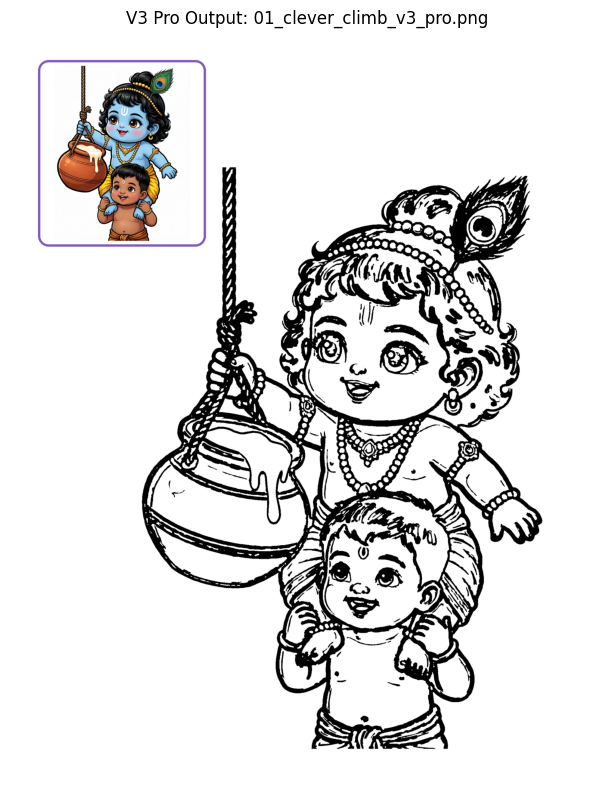

In [86]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image, ImageDraw, ImageOps
import matplotlib.pyplot as plt

# =====================================================================
# 1. ONLY CHANGE THESE TWO LINES EACH TIME YOU RUN:
# =====================================================================
SOURCE_FILENAME = "ComfyUI_00001_.png"          # <-- Your generated color image
OUTPUT_FILENAME = "01_clever_climb_v3_pro.png"  # <-- Output file name
# =====================================================================

search_dirs = [Path("/kaggle/working/ComfyUI/output"), Path("/kaggle/working")]
input_path = next((d / SOURCE_FILENAME for d in search_dirs if (d / SOURCE_FILENAME).exists()), None)

if input_path is None:
    raise FileNotFoundError(f"Could not find {SOURCE_FILENAME}. Check the filename!")

def make_pro_kdp_coloring_page(color_path, out_name):
    # 1. Load original image and upscale 2x FIRST for smooth, non-blobby vector-quality lines
    img_bgr = cv2.imread(str(color_path))
    h0, w0 = img_bgr.shape[:2]
    img_up = cv2.resize(img_bgr, (w0 * 2, h0 * 2), interpolation=cv2.INTER_CUBIC)
    
    gray = cv2.cvtColor(img_up, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(img_up, cv2.COLOR_BGR2HSV)
    
    # 2. Extract crisp dark ink lines AND color-boundary edges (keeps white Tilak on blue skin!)
    # Channel A: Luminance gentle smoothing
    smooth_gray = cv2.bilateralFilter(gray, d=9, sigmaColor=45, sigmaSpace=45)
    edges_gray = cv2.adaptiveThreshold(
        smooth_gray, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        blockSize=25,  # At 2x resolution, 25 gives crisp, non-blobby cartoon lines
        C=6
    )
    
    # Channel B: Saturation edge detection specifically to catch the white Tilak on blue forehead!
    sat = hsv[:, :, 1]
    smooth_sat = cv2.bilateralFilter(sat, d=9, sigmaColor=45, sigmaSpace=45)
    edges_sat = cv2.adaptiveThreshold(
        smooth_sat, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        blockSize=25,
        C=8
    )
    
    # Combine luminance lines + saturation lines (so Tilak & pot patterns are never lost)
    raw_lines = cv2.bitwise_and(edges_gray, edges_sat)
    
    # 3. SURGICAL HAIR CLEANUP: Find ONLY the large dark hair mass and hollow its inside
    # Hair is very dark (gray < 50). We find connected blobs: huge blobs = hair, small blobs = eyes!
    _, very_dark = cv2.threshold(smooth_gray, 52, 255, cv2.THRESH_BINARY_INV)
    num_l, labels, stats, _ = cv2.connectedComponentsWithStats(very_dark, connectivity=8)
    
    hair_mask = np.zeros_like(gray)
    pupil_mask = np.zeros_like(gray)
    
    for i in range(1, num_l):
        area = stats[i, cv2.CC_STAT_AREA]
        w_box, h_box = stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]
        aspect = w_box / float(h_box) if h_box > 0 else 0
        
        if area > 12000:
            # Large dark region -> This is HAIR!
            hair_mask[labels == i] = 255
        elif 250 < area < 6500 and 0.45 < aspect < 2.1:
            # Compact round dark region -> This is an EYE PUPIL/IRIS!
            pupil_mask[labels == i] = 255

    # Erode the hair mask by 10px so we KEEP a thick black outer hair outline,
    # and only erase the scratchy lines deep INSIDE the hair
    kernel_hair = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (19, 19))
    hair_interior = cv2.erode(hair_mask, kernel_hair, iterations=1)
    
    # Also clean inside the peacock feather eye-spot (keep outer rings, remove fine barbs)
    raw_lines[hair_interior == 255] = 255
    
    # 4. Fix the Eyes: Fill both pupils solid black, then punch back the cute white sparkle dots!
    # Erode pupil_mask slightly so eyelashes don't turn into giant black blobs
    clean_pupils = cv2.erode(pupil_mask, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)), iterations=1)
    raw_lines[clean_pupils == 255] = 0
    
    # Restore white eye catchlights (bright white reflections inside the eyes where gray > 200)
    _, eye_sparkles = cv2.threshold(gray, 190, 255, cv2.THRESH_BINARY)
    raw_lines[eye_sparkles == 255] = 255
    
    # 5. Remove tiny stray speckles/dots without hurting beads or fingers
    inv = 255 - raw_lines
    nl, lbls, st, _ = cv2.connectedComponentsWithStats(inv, connectivity=8)
    clean_inv = np.zeros_like(inv)
    for i in range(1, nl):
        if st[i, cv2.CC_STAT_AREA] >= 95:  # Removes tiny skin/pot speckles
            clean_inv[lbls == i] = 255
            
    # Smooth jagged pixel edges with a gentle morphological close (NO heavy dilation!)
    smooth_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    clean_inv = cv2.morphologyEx(clean_inv, cv2.MORPH_CLOSE, smooth_kernel)
    final_bw = 255 - cv2.medianBlur(clean_inv, 3)
    
    # 6. Assemble on 8.5" x 11" KDP Canvas (2550 x 3300 at 300 DPI)
    line_pil = Image.fromarray(final_bw).convert("RGB")
    color_pil = Image.open(color_path).convert("RGB")
    
    page_w, page_h = 2550, 3300
    canvas = Image.new("RGB", (page_w, page_h), "white")
    
    main_max_w = int(page_w * 0.76)
    main_max_h = int(page_h * 0.78)
    line_resized = ImageOps.contain(line_pil, (main_max_w, main_max_h), Image.Resampling.LANCZOS)
    
    paste_x = max(520, (page_w - line_resized.width) // 2 + 180)
    paste_y = 580
    canvas.paste(line_resized, (paste_x, paste_y))
    
    # 7. Build Top-Left Color Reference Box
    box_w, box_h = 720, 800
    thumb_box = Image.new("RGBA", (box_w, box_h), (0, 0, 0, 0))
    draw = ImageDraw.Draw(thumb_box)
    draw.rounded_rectangle(
        [(0, 0), (box_w - 1, box_h - 1)],
        radius=45,
        fill="white",
        outline="#7E57C2",
        width=10
    )
    
    thumb_img = ImageOps.contain(color_pil, (box_w - 50, box_h - 50), Image.Resampling.LANCZOS)
    tx = (box_w - thumb_img.width) // 2
    ty = (box_h - thumb_img.height) // 2
    thumb_box.paste(thumb_img, (tx, ty))
    canvas.paste(thumb_box, (120, 120), thumb_box)
    
    # 8. Save & Preview
    out_dir = Path("/kaggle/working/04_book_output")
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / out_name
    canvas.save(out_path, dpi=(300, 300))
    print(f"✅ Saved high-precision coloring page: {out_path}")
    
    plt.figure(figsize=(8, 10))
    plt.imshow(canvas)
    plt.axis("off")
    plt.title(f"V3 Pro Output: {out_name}")
    plt.show()

make_pro_kdp_coloring_page(input_path, OUTPUT_FILENAME)

✅ Saved V5 Safe Coloring Page: /kaggle/working/04_book_output/01_clever_climb_v5_fixed.png


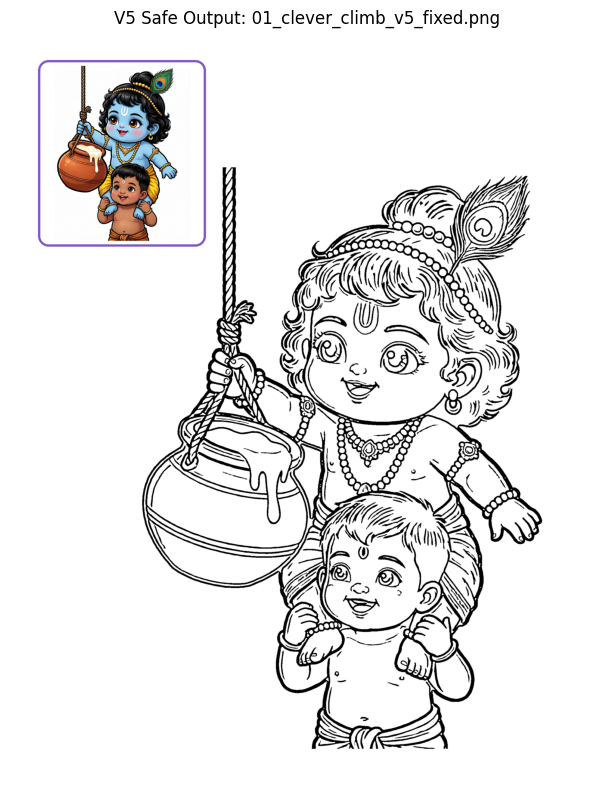

In [93]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image, ImageDraw, ImageOps
import matplotlib.pyplot as plt

# =====================================================================
# 1. ONLY CHANGE THESE TWO LINES EACH TIME YOU RUN:
# =====================================================================
SOURCE_FILENAME = "ComfyUI_00001_.png"             # <-- Your source color image
OUTPUT_FILENAME = "01_clever_climb_v5_fixed.png"   # <-- Output file name
# =====================================================================

search_dirs = [Path("/kaggle/working/ComfyUI/output"), Path("/kaggle/working")]
input_path = next((d / SOURCE_FILENAME for d in search_dirs if (d / SOURCE_FILENAME).exists()), None)

if input_path is None:
    raise FileNotFoundError(f"Could not find {SOURCE_FILENAME}. Check the filename!")

def make_v5_safe_coloring_page(color_path, out_name):
    # 1. Load image and upscale 2x for smooth lines
    img_bgr = cv2.imread(str(color_path))
    h0, w0 = img_bgr.shape[:2]
    img_up = cv2.resize(img_bgr, (w0 * 2, h0 * 2), interpolation=cv2.INTER_CUBIC)
    
    gray = cv2.cvtColor(img_up, cv2.COLOR_BGR2GRAY)
    
    # 2. Gentle Bilateral Filter to smooth color gradients while keeping ink edges razor sharp
    smooth = cv2.bilateralFilter(gray, d=9, sigmaColor=50, sigmaSpace=50)
    
    # 3. Clean Adaptive Thresholding (Safely extracts all lines without erasing faces)
    # This preserves eyes, nose, mouth, tilak, jewelry, and outlines together.
    lines = cv2.adaptiveThreshold(
        smooth, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        blockSize=19,
        C=5
    )
    
    # 4. Lightly soften heavy internal hair scratchiness WITHOUT touching the face
    # We target only very dark pixels (hair) and apply a gentle median blur to merge minor strands
    _, dark_hair = cv2.threshold(smooth, 45, 255, cv2.THRESH_BINARY_INV)
    # Only blur inside large hair clusters, keeping facial features strictly protected
    num_l, labels, stats, _ = cv2.connectedComponentsWithStats(dark_hair, connectivity=8)
    
    hair_cleanup_mask = np.zeros_like(gray)
    for i in range(1, num_l):
        if stats[i, cv2.CC_STAT_AREA] > 8000: # Giant blobs = hair
            hair_cleanup_mask[labels == i] = 255
            
    # Apply local smoothing strictly to hair regions to reduce scratchy strokes
    hair_smoothed = cv2.medianBlur(lines, 5)
    lines[hair_cleanup_mask == 255] = hair_smoothed[hair_cleanup_mask == 255]
    
    # 5. Despeckle: Remove tiny stray dots (< 120 pixels) while keeping all facial lines intact
    inv = 255 - lines
    nl, lbls, st, _ = cv2.connectedComponentsWithStats(inv, connectivity=8)
    clean_inv = np.zeros_like(inv)
    for i in range(1, nl):
        if st[i, cv2.CC_STAT_AREA] >= 120:
            clean_inv[lbls == i] = 255
            
    final_bw = 255 - clean_inv
    
    # 6. Place on 8.5" x 11" KDP Canvas (2550 x 3300 at 300 DPI)
    line_pil = Image.fromarray(final_bw).convert("RGB")
    color_pil = Image.open(color_path).convert("RGB")
    
    page_w, page_h = 2550, 3300
    canvas = Image.new("RGB", (page_w, page_h), "white")
    
    main_max_w = int(page_w * 0.76)
    main_max_h = int(page_h * 0.78)
    line_resized = ImageOps.contain(line_pil, (main_max_w, main_max_h), Image.Resampling.LANCZOS)
    
    paste_x = max(520, (page_w - line_resized.width) // 2 + 180)
    paste_y = 580
    canvas.paste(line_resized, (paste_x, paste_y))
    
    # 7. Add Top-Left Color Reference Box (Matching Volume 1 style)
    box_w, box_h = 720, 800
    thumb_box = Image.new("RGBA", (box_w, box_h), (0, 0, 0, 0))
    draw = ImageDraw.Draw(thumb_box)
    draw.rounded_rectangle(
        [(0, 0), (box_w - 1, box_h - 1)],
        radius=45,
        fill="white",
        outline="#7E57C2",
        width=10
    )
    
    thumb_img = ImageOps.contain(color_pil, (box_w - 50, box_h - 50), Image.Resampling.LANCZOS)
    tx = (box_w - thumb_img.width) // 2
    ty = (box_h - thumb_img.height) // 2
    thumb_box.paste(thumb_img, (tx, ty))
    canvas.paste(thumb_box, (120, 120), thumb_box)
    
    # 8. Save & Show Preview
    out_dir = Path("/kaggle/working/04_book_output")
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / out_name
    canvas.save(out_path, dpi=(300, 300))
    print(f"✅ Saved V5 Safe Coloring Page: {out_path}")
    
    plt.figure(figsize=(8, 10))
    plt.imshow(canvas)
    plt.axis("off")
    plt.title(f"V5 Safe Output: {out_name}")
    plt.show()

make_v5_safe_coloring_page(input_path, OUTPUT_FILENAME)

🧠 Smart Placement: Placed reference thumbnail on the Right side based on whitespace.
✅ Saved clean coloring page to: /kaggle/working/04_book_output/01_clever_climb_v6_smart.png


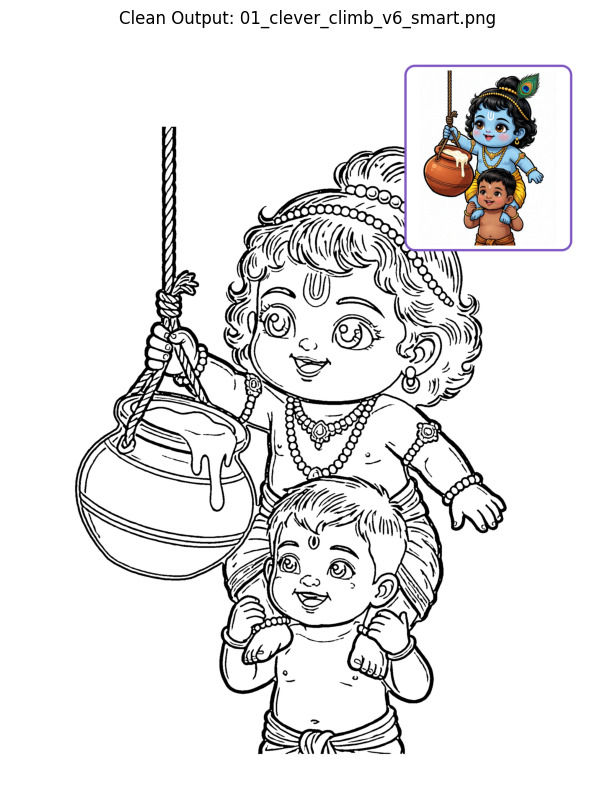

In [92]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image, ImageDraw, ImageOps
import matplotlib.pyplot as plt

# =====================================================================
# 1. ONLY CHANGE THESE TWO LINES EACH TIME YOU RUN:
# =====================================================================
SOURCE_FILENAME = "ComfyUI_00001_.png"          # <-- Your source color image
OUTPUT_FILENAME = "01_clever_climb_v6_smart.png" # <-- Output file name
INCLUDE_AUTO_THUMBNAIL = False                 # <-- Set to True if you want the script 
                                               #     to automatically place the thumbnail 
                                               #     on the side with more whitespace!
# =====================================================================

search_dirs = [Path("/kaggle/working/ComfyUI/output"), Path("/kaggle/working")]
input_path = next((d / SOURCE_FILENAME for d in search_dirs if (d / SOURCE_FILENAME).exists()), None)

if input_path is None:
    raise FileNotFoundError(f"Could not find {SOURCE_FILENAME}. Check the filename in your ComfyUI output folder!")

def make_smart_coloring_page(color_path, out_name, auto_thumbnail=False):
    # 1. Load image and upscale 2x for smooth, crisp vector lines
    img_bgr = cv2.imread(str(color_path))
    h0, w0 = img_bgr.shape[:2]
    img_up = cv2.resize(img_bgr, (w0 * 2, h0 * 2), interpolation=cv2.INTER_CUBIC)
    
    gray = cv2.cvtColor(img_up, cv2.COLOR_BGR2GRAY)
    
    # 2. Gentle Bilateral Filter to smooth color gradients while keeping ink edges razor sharp
    smooth = cv2.bilateralFilter(gray, d=9, sigmaColor=50, sigmaSpace=50)
    
    # 3. Clean Adaptive Thresholding (Safely extracts all lines without erasing faces)
    lines = cv2.adaptiveThreshold(
        smooth, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY,
        blockSize=19,
        C=5
    )
    
    # 4. Lightly soften heavy internal hair scratchiness WITHOUT touching facial features
    _, dark_hair = cv2.threshold(smooth, 45, 255, cv2.THRESH_BINARY_INV)
    num_l, labels, stats, _ = cv2.connectedComponentsWithStats(dark_hair, connectivity=8)
    
    hair_cleanup_mask = np.zeros_like(gray)
    for i in range(1, num_l):
        if stats[i, cv2.CC_STAT_AREA] > 8000:  # Giant blobs = hair
            hair_cleanup_mask[labels == i] = 255
            
    hair_smoothed = cv2.medianBlur(lines, 5)
    lines[hair_cleanup_mask == 255] = hair_smoothed[hair_cleanup_mask == 255]
    
    # 5. Despeckle: Remove tiny stray dots (< 120 pixels) while keeping all lines intact
    inv = 255 - lines
    nl, lbls, st, _ = cv2.connectedComponentsWithStats(inv, connectivity=8)
    clean_inv = np.zeros_like(inv)
    for i in range(1, nl):
        if st[i, cv2.CC_STAT_AREA] >= 120:
            clean_inv[lbls == i] = 255
            
    final_bw = 255 - clean_inv
    
    # 6. Place on 8.5" x 11" KDP Canvas (2550 x 3300 at 300 DPI)
    line_pil = Image.fromarray(final_bw).convert("RGB")
    color_pil = Image.open(color_path).convert("RGB")
    
    page_w, page_h = 2550, 3300
    canvas = Image.new("RGB", (page_w, page_h), "white")
    
    # Resize and center the main coloring artwork nicely on the page
    main_max_w = int(page_w * 0.82)
    main_max_h = int(page_h * 0.82)
    line_resized = ImageOps.contain(line_pil, (main_max_w, main_max_h), Image.Resampling.LANCZOS)
    
    paste_x = (page_w - line_resized.width) // 2
    paste_y = (page_h - line_resized.height) // 2 + 100
    canvas.paste(line_resized, (paste_x, paste_y))
    
    # 7. Optional Smart Dynamic Thumbnail Placement (If enabled)
    if auto_thumbnail:
        box_w, box_h = 720, 800
        
        # Analyze top-left vs top-right whitespace on the placed line art to avoid overlapping
        crop_h = int(page_h * 0.35)
        top_left_region = final_bw[:crop_h, :page_w//2]
        top_right_region = final_bw[:crop_h, page_w//2:]
        
        left_ink_density = np.sum(top_left_region == 0)
        right_ink_density = np.sum(top_right_region == 0)
        
        # Choose the side with LESS ink density (more open whitespace)
        if left_ink_density <= right_ink_density:
            thumb_x = 140  # Snap to Top-Left
        else:
            thumb_x = page_w - box_w - 140  # Snap to Top-Right
            
        thumb_y = 140
        
        # Build the purple-bordered reference box
        thumb_box = Image.new("RGBA", (box_w, box_h), (0, 0, 0, 0))
        draw = ImageDraw.Draw(thumb_box)
        draw.rounded_rectangle(
            [(0, 0), (box_w - 1, box_h - 1)],
            radius=45,
            fill="white",
            outline="#7E57C2",
            width=10
        )
        
        thumb_img = ImageOps.contain(color_pil, (box_w - 50, box_h - 50), Image.Resampling.LANCZOS)
        tx = (box_w - thumb_img.width) // 2
        ty = (box_h - thumb_img.height) // 2
        thumb_box.paste(thumb_img, (tx, ty))
        canvas.paste(thumb_box, (thumb_x, thumb_y), thumb_box)
        print(f"🧠 Smart Placement: Placed reference thumbnail on the {'Left' if thumb_x == 140 else 'Right'} side based on whitespace.")

    # 8. Save & Show Preview
    out_dir = Path("/kaggle/working/04_book_output")
    out_dir.mkdir(parents=True, exist_ok=True)
    out_path = out_dir / out_name
    canvas.save(out_path, dpi=(300, 300))
    print(f"✅ Saved clean coloring page to: {out_path}")
    
    plt.figure(figsize=(8, 10))
    plt.imshow(canvas)
    plt.axis("off")
    plt.title(f"Clean Output: {out_name}")
    plt.show()

make_smart_coloring_page(input_path, OUTPUT_FILENAME, auto_thumbnail=INCLUDE_AUTO_THUMBNAIL)